# Decision Tree — Breast Cancer Wisconsin (Diagnostic)
**Student:** Andrea Elizondo Ocañas  
**Student ID:** 2096175  
**Class day and time:** Tuesday N4  


## 1. Load libraries

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

## 2. Load data
The dataset contains 569 samples, 30 numeric features, and two target classes: malignant (0) and benign (1).

In [3]:
dataset = load_breast_cancer()
data = dataset.data
labels = dataset.target
print("Data shape:", data.shape)
print("Classes:", dataset.target_names)

Data shape: (569, 30)
Classes: ['malignant' 'benign']


## 3. Data preprocessing
Split the data into 80% training and 20% testing, preserving the class proportions with `stratify`.

In [4]:
train_data, test_data, train_labels, test_label = train_test_split(
    data, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 455
Testing samples: 114


## 4. Model selection and training
A depth limit of four helps keep the decision tree interpretable and reduces the risk of overfitting.

In [5]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(train_data, train_labels)

DecisionTreeClassifier(max_depth=4, random_state=42)

## 5. Model testing
Use the held-out test set for predictions. Report accuracy, precision, recall and F1-score.

In [6]:
predictions = model.predict(test_data)
accuracy = accuracy_score(test_label, predictions)
print(f"Test accuracy: {accuracy:.4f} ({accuracy:.2%})")
print("\nClassification report:\n")
print(classification_report(test_label, predictions, target_names=dataset.target_names, zero_division=0))

Test accuracy: 0.9386 (93.86%)

Classification report:

              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



## Decision tree visualization (300 DPI)
The figure is saved as a PNG at 300 DPI for use in the report.

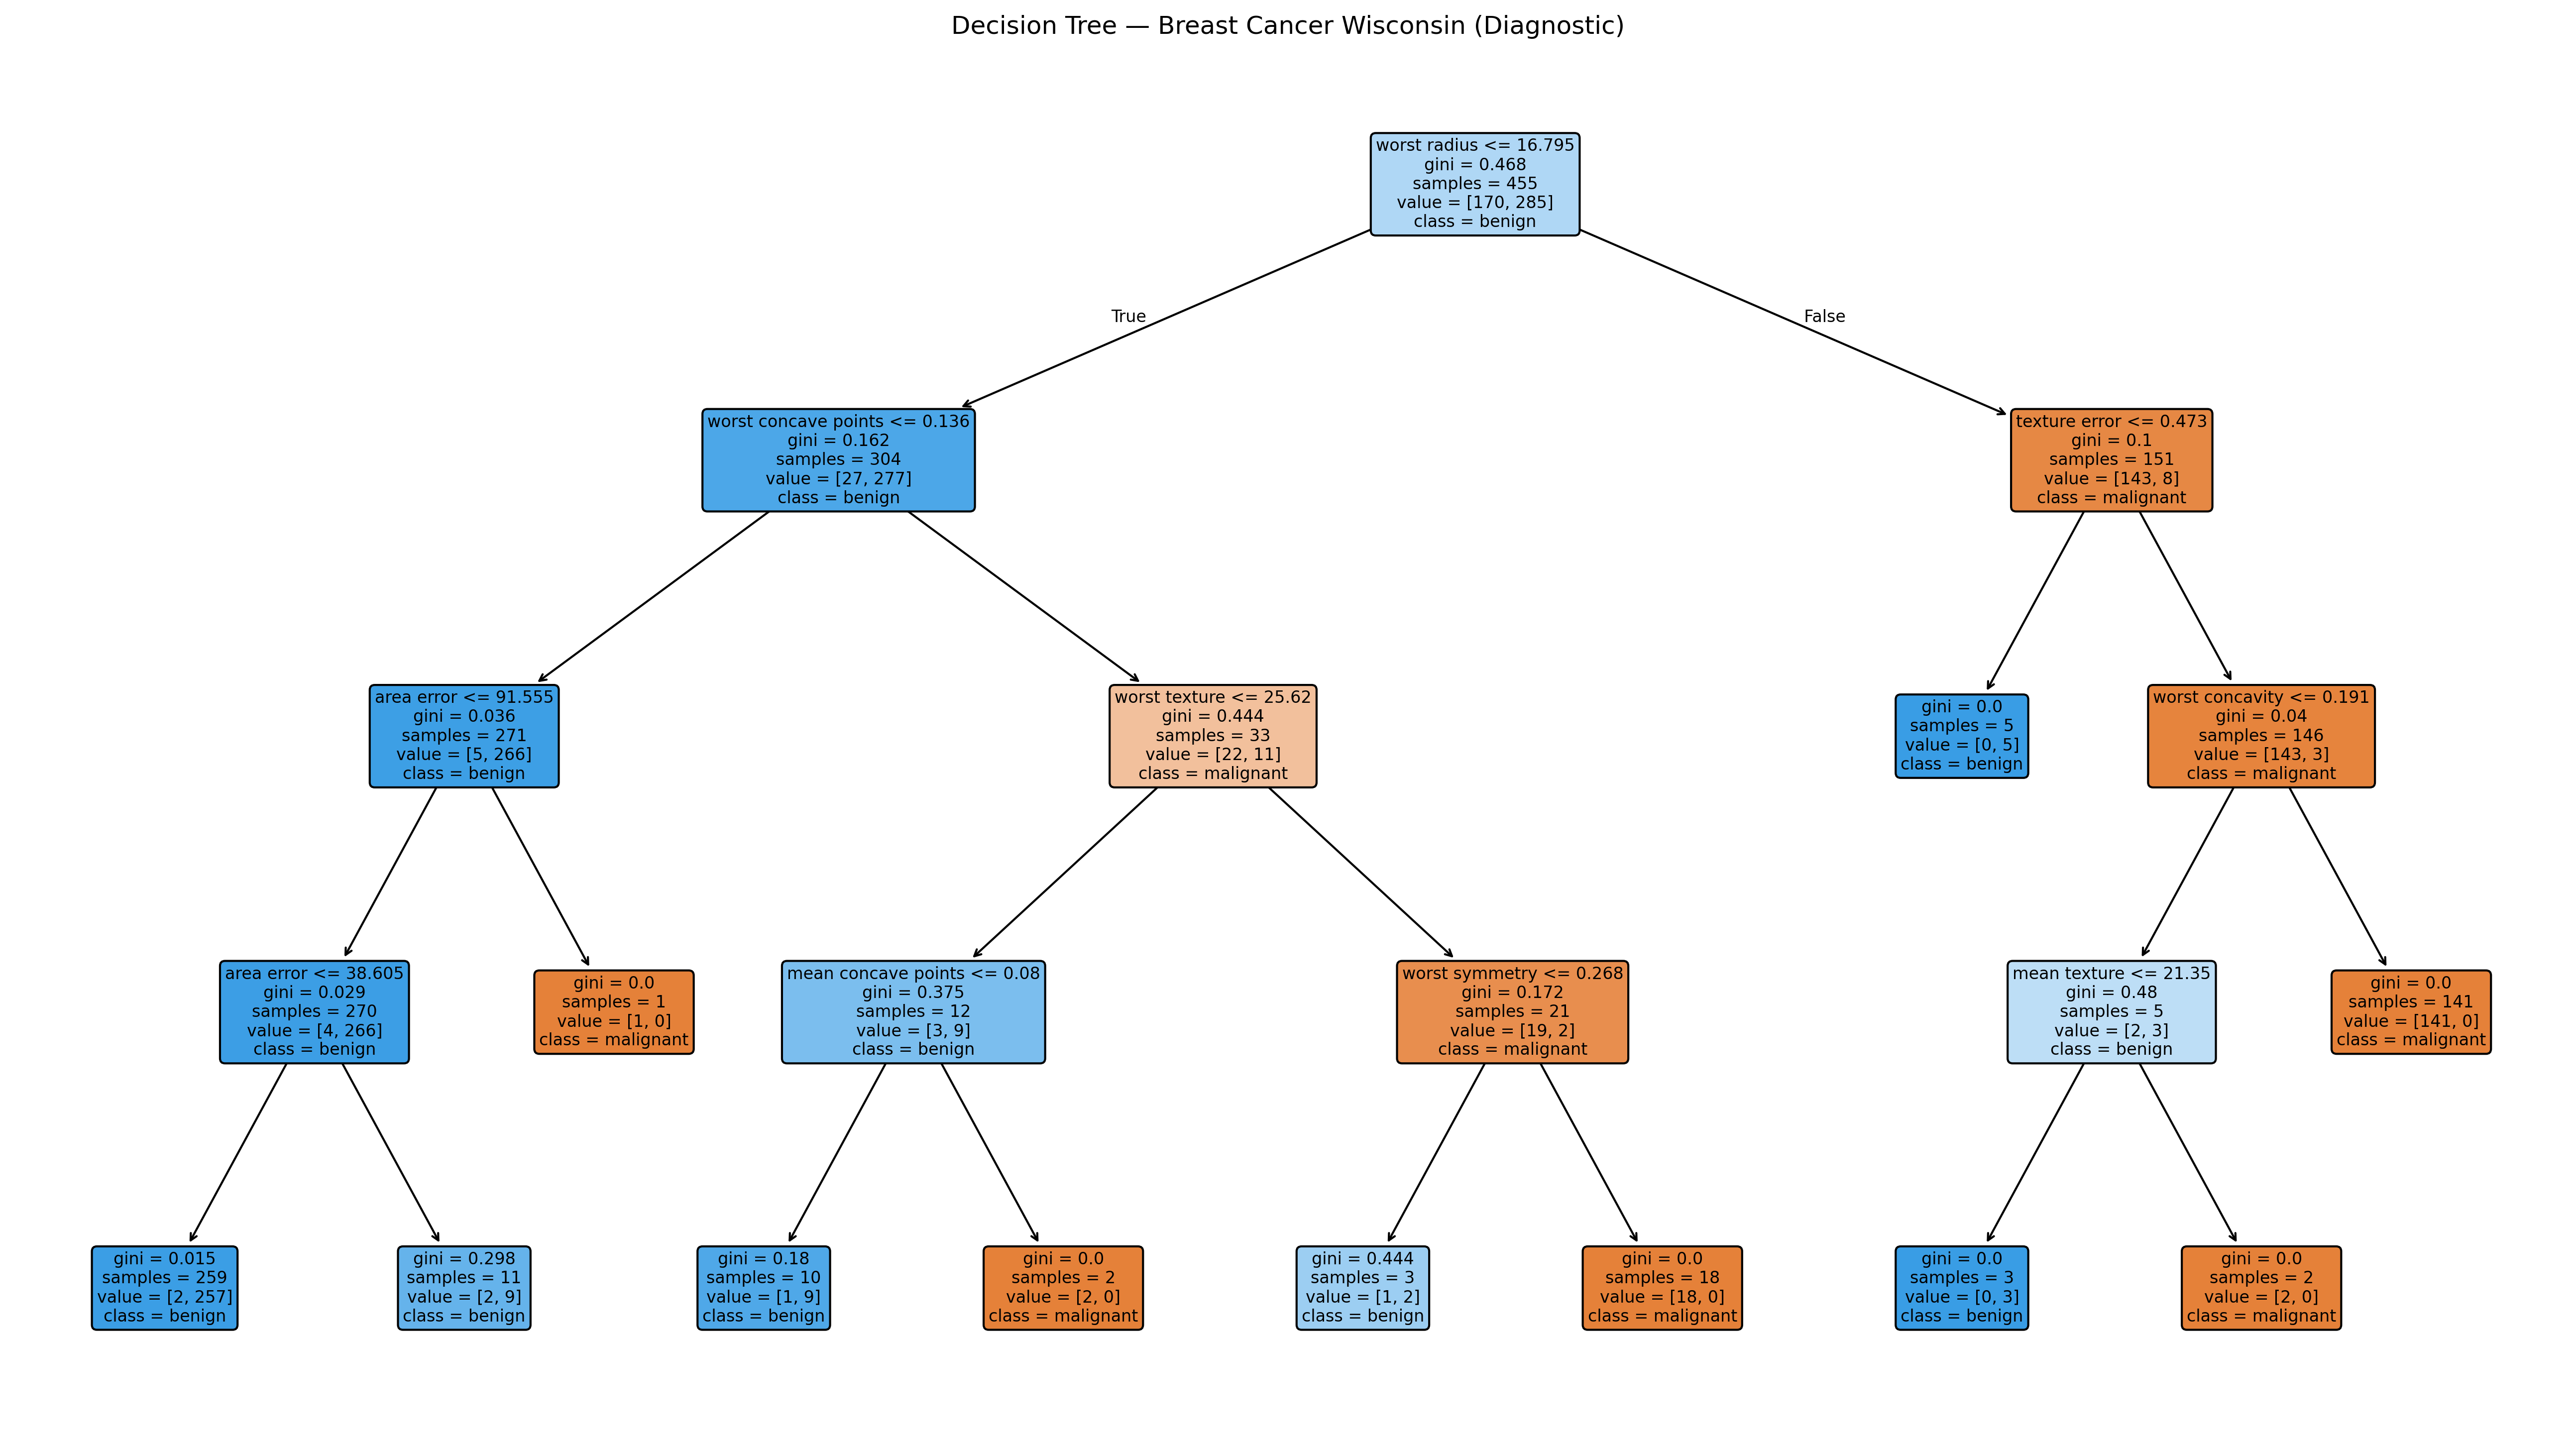

In [7]:
plt.figure(figsize=(22, 12), dpi=300)
plot_tree(model, feature_names=dataset.feature_names, class_names=dataset.target_names,
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree — Breast Cancer Wisconsin (Diagnostic)")
plt.savefig("Decision_Tree_300dpi.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretation
The test accuracy measures the proportion of correctly classified cases. Precision, recall and F1-score provide class-specific context; in a medical screening setting, recall for malignant cases is particularly important. This educational model is not suitable for clinical diagnosis without further validation.

**References:** Géron (2022), *Hands-On Machine Learning*; Matthes (2023), *Python Crash Course*; scikit-learn documentation.